In [4]:
!pip -q install scikit-learn openpyxl


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
file_path = "/content/RetailIQ_Final.xlsx"

sheets = pd.read_excel(file_path, sheet_name=None)

df1 = sheets["Year 2009-2010"]
df2 = sheets["Year 2010-2011"]

# Combine both sheets
df_combined = pd.concat(
    [df1, df2],
    ignore_index=True
)

# Remove exact duplicate records across sheets
df_combined = df_combined.drop_duplicates().reset_index(drop=True)

# Convert data types
df_combined["InvoiceDate"] = pd.to_datetime(
    df_combined["InvoiceDate"]
)

df_combined["Revenue"] = pd.to_numeric(
    df_combined["Revenue"],
    errors="coerce"
)

print("Combined Dataset Shape:", df_combined.shape)
print("Duplicate Records:", df_combined.duplicated().sum())
print("Total Revenue:", df_combined["Revenue"].sum())

Combined Dataset Shape: (1033036, 14)
Duplicate Records: 0
Total Revenue: 20476260.448000003


In [7]:
customer_data = df_combined[
    (df_combined["IsCancelled"] == False) &
    (df_combined["CustomerID"].notna()) &
    (df_combined["Revenue"] > 0)
].copy()

print("Customer Transaction Records:", len(customer_data))

print(
    "Unique Customers:",
    customer_data["CustomerID"].nunique()
)

print(
    "Unique Invoices:",
    customer_data["InvoiceNo"].nunique()
)

Customer Transaction Records: 779425
Unique Customers: 5878
Unique Invoices: 36969


In [8]:
reference_date = (
    df_combined["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

rfm = customer_data.groupby("CustomerID").agg({

    "InvoiceDate": lambda x: (
        reference_date - x.max()
    ).days,

    "InvoiceNo": "nunique",

    "Revenue": "sum"

})

rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

print(rfm.head())
print("\nRFM Shape:", rfm.shape)

            Recency  Frequency  Monetary
CustomerID                              
12,346.00       326         12 77,556.46
12,347.00         2          8  4,921.53
12,348.00        75          5  2,019.40
12,349.00        19          4  4,428.69
12,350.00       310          1    334.40

RFM Shape: (5878, 3)


In [9]:
# Recency: lower is better
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher is better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher is better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
"12,346.00",326,12,"77,556.46",2,5,5,255
"12,347.00",2,8,"4,921.53",5,4,5,545
"12,348.00",75,5,"2,019.40",3,4,4,344
"12,349.00",19,4,"4,428.69",5,3,5,535
"12,350.00",310,1,334.40,2,1,2,212


In [10]:
conditions = [

    (
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 4) &
        (rfm["M_Score"] >= 4)
    ),

    (rfm["F_Score"] >= 4),

    (
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 2)
    ),

    (
        (rfm["R_Score"] == 5) &
        (rfm["F_Score"] == 1)
    ),

    (
        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] >= 3)
    ),

    (
        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] <= 2)
    ),

    (
        (rfm["R_Score"] == 3) &
        (rfm["F_Score"] <= 3)
    )
]

segment_names = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "New Customers",
    "At Risk",
    "Hibernating",
    "Need Attention"
]

rfm["RFM_Segment"] = np.select(
    conditions,
    segment_names,
    default="Others"
)

print(rfm["RFM_Segment"].value_counts())

RFM_Segment
Hibernating            1526
Champions              1289
Loyal Customers        1062
Potential Loyalists     711
Need Attention          652
At Risk                 471
Others                  113
New Customers            54
Name: count, dtype: int64


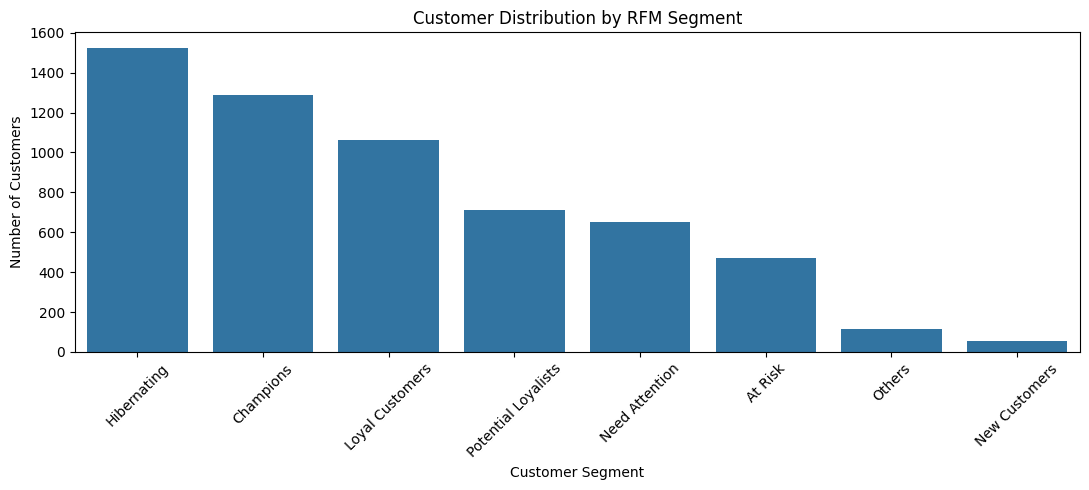

In [11]:
segment_counts = rfm["RFM_Segment"].value_counts()

plt.figure(figsize=(11, 5))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Log transformation
rfm_log = np.log1p(rfm_features)

# Standardization
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled Data Shape:", rfm_scaled.shape)

Scaled Data Shape: (5878, 3)


In [13]:
inertia_values = []
silhouette_values = []

k_values = range(2, 8)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(rfm_scaled, labels)
    )

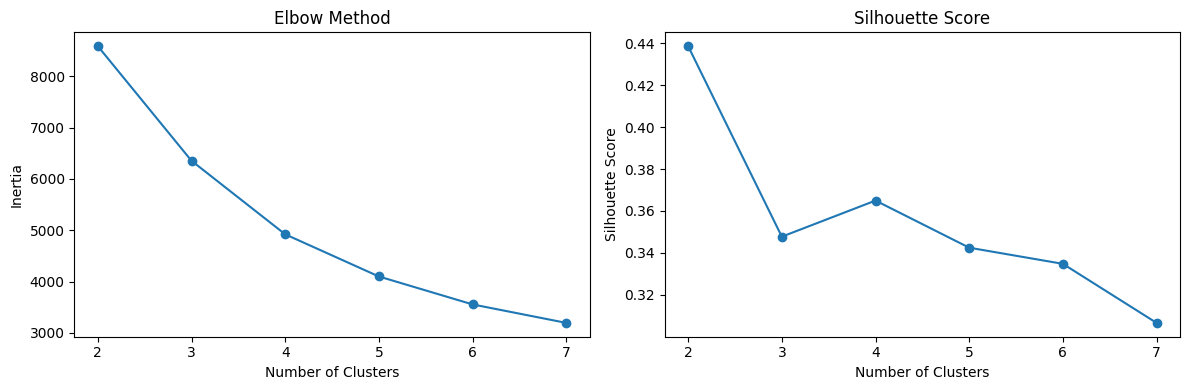

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [15]:
best_k = list(k_values)[
    np.argmax(silhouette_values)
]

print("Selected Number of Clusters:", best_k)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print(
    "Final Silhouette Score:",
    silhouette_score(rfm_scaled, rfm["Cluster"])
)

Selected Number of Clusters: 2
Final Silhouette Score: 0.4386023012270002


In [16]:
cluster_profile = rfm.groupby("Cluster").agg(

    Customer_Count=("Recency", "count"),

    Avg_Recency=("Recency", "mean"),

    Avg_Frequency=("Frequency", "mean"),

    Avg_Monetary=("Monetary", "mean"),

    Median_Monetary=("Monetary", "median"),

    Avg_RFM_Score=("RFM_Score", "count")

)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] /
    len(rfm) * 100
)

cluster_profile = cluster_profile.round(2)

cluster_profile

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Avg_RFM_Score,Customer_Percentage
Cluster,,,,,,,
0,3558,299.65,2.10,614.34,415.80,3558,60.53
1,2320,50.56,12.72,"6,546.97","2,861.48",2320,39.47


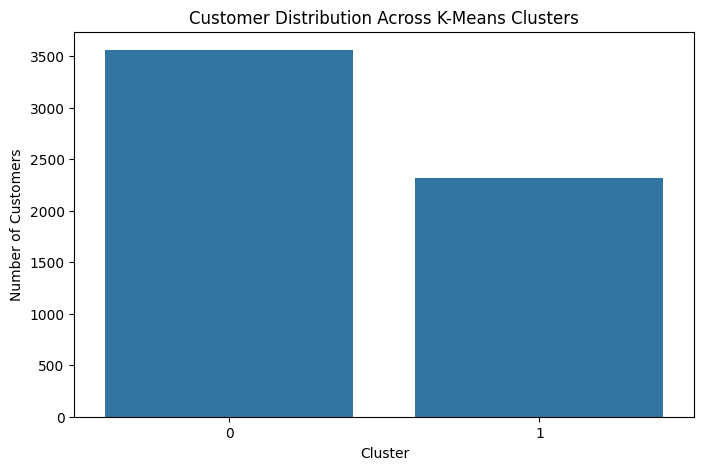

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Cluster"
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

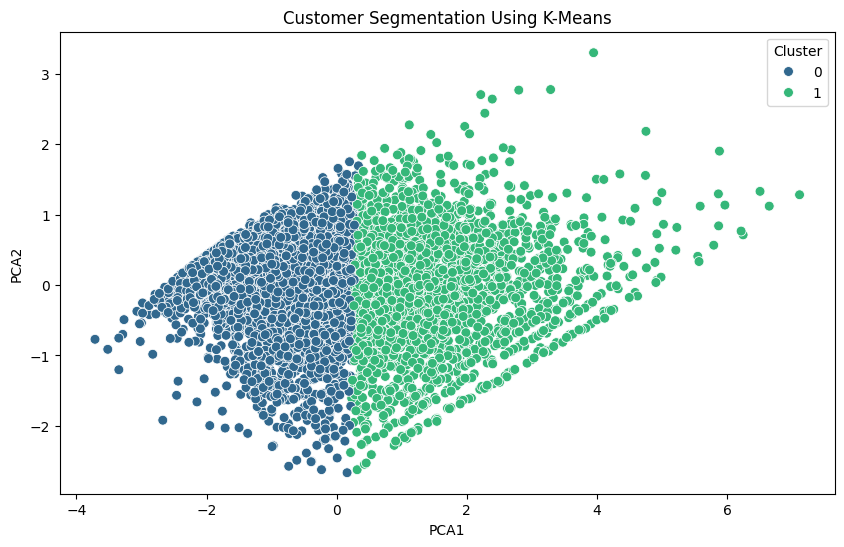

Explained Variance: 0.9510113649304764


In [18]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(rfm_scaled)

rfm["PCA1"] = pca_data[:, 0]
rfm["PCA2"] = pca_data[:, 1]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="viridis",
    s=50
)

plt.title("Customer Segmentation Using K-Means")
plt.show()

print(
    "Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

In [19]:
comparison = pd.crosstab(
    rfm["RFM_Segment"],
    rfm["Cluster"]
)

comparison

Cluster,0,1
RFM_Segment,,
At Risk,468,3
Champions,0,1289
Hibernating,1525,1
Loyal Customers,354,708
Need Attention,622,30
New Customers,52,2
Others,113,0
Potential Loyalists,424,287


In [20]:
rfm.to_csv(
    "customer_rfm_kmeans_results.csv"
)

cluster_profile.to_csv(
    "customer_cluster_profiles.csv"
)

print("Customer analysis completed.")

Customer analysis completed.
